# Iris Flower Classification Using Machine Learning

## 1. Project Idea

The aim of this project is to develop a machine learning model that predicts the species of an iris flower using its physical measurements.

The dataset contains four features: sepal length, sepal width, petal length, and petal width. The model predicts one of three species: Iris setosa, Iris versicolor, or Iris virginica.

This project demonstrates how machine learning can identify patterns in data and use them to classify new examples. It introduces the basic steps of a machine learning workflow, from data preparation to model evaluation.



## 2. Data Preparation

The Iris dataset is loaded using Scikit-learn. The data is inspected to understand its features and target variable, and missing values are checked to ensure the dataset is suitable for training.

The four flower measurements are used as input features (`X`), while the flower species is the target (`y`). The dataset is then divided into training and testing sets using an 80:20 split, allowing the models to be evaluated on data they did not train on.

In [ ]:

# Data handling and visualization
import pandas as pd
import matplotlib.pyplot as plt

# Dataset and train-test splitting
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split

# Machine learning models
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier

# Model evaluation
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay


In [ ]:

# Load the built-in Iris dataset
iris = load_iris()

# Display the dataset description
print("Dataset loaded successfully!")
print("Flower species:", iris.target_names)


Dataset loaded successfully!
Flower species: ['setosa' 'versicolor' 'virginica']


In [ ]:

# Create the feature table
X = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)

# Create the target labels
y = iris.target

print("Number of records:", X.shape[0])
print("Number of features:", X.shape[1])

print("\nFirst five records:")
display(X.head())

print("\nTarget species:")
print(iris.target_names)


Number of records: 150
Number of features: 4

First five records:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2



Target species:
['setosa' 'versicolor' 'virginica']


In [ ]:

# Count missing values in each feature
missing_values = X.isnull().sum()

print("Missing values in each column:")
print(missing_values)

print("\nTotal missing values:", missing_values.sum())


Missing values in each column:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
dtype: int64

Total missing values: 0


In [ ]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])


Training records: 120
Testing records: 30


## 3. Model Building

Two supervised machine learning classification models are implemented.

- **Decision Tree:** Learns decision rules from the training data to predict the flower species.
- **K-Nearest Neighbors (KNN):** Predicts the species based on the labels of the nearest training samples. In this project, KNN uses five neighbors (`k = 5`).

Both models are trained using the same training dataset so that their performance can be compared fairly.

In [ ]:

# Create the Decision Tree model
decision_tree = DecisionTreeClassifier(random_state=42)

# Train the model
decision_tree.fit(X_train, y_train)

# Predict species for the test data
dt_predictions = decision_tree.predict(X_test)

print("Decision Tree model trained successfully!")


Decision Tree model trained successfully!


In [ ]:

# Create the KNN model
knn = KNeighborsClassifier(n_neighbors=5)

# Train the model
knn.fit(X_train, y_train)

# Predict species for the test data
knn_predictions = knn.predict(X_test)

print("KNN model trained successfully!")


KNN model trained successfully!


## 4. Evaluation

The trained models are evaluated using accuracy and confusion matrices. Accuracy measures the proportion of test samples classified correctly, while a confusion matrix shows the correct and incorrect predictions for each flower species.

Comparing these metrics helps identify which model performed better on the selected test dataset.

In [ ]:

# Calculate model accuracy
dt_accuracy = accuracy_score(y_test, dt_predictions)
knn_accuracy = accuracy_score(y_test, knn_predictions)

# Compare the results
results = pd.DataFrame({
    "Model": ["Decision Tree", "KNN"],
    "Accuracy (%)": [
        dt_accuracy * 100,
        knn_accuracy * 100
    ]
})

display(results.round(2))


,Model,Accuracy (%)
0,Decision Tree,93.33
1,KNN,100.00


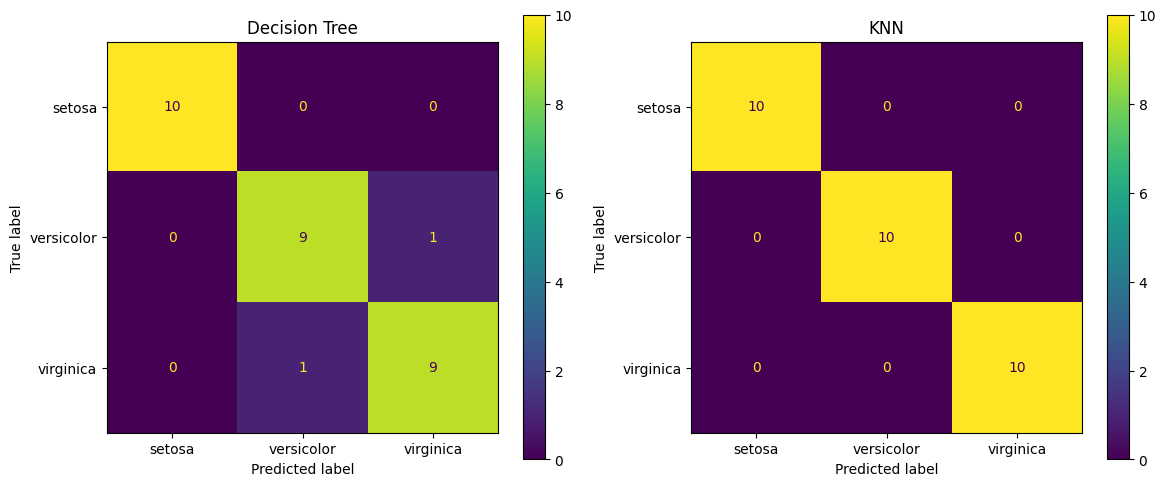

In [ ]:

# Create two confusion matrices side by side
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    dt_predictions,
    display_labels=iris.target_names,
    ax=axes[0]
)
axes[0].set_title("Decision Tree")

ConfusionMatrixDisplay.from_predictions(
    y_test,
    knn_predictions,
    display_labels=iris.target_names,
    ax=axes[1]
)
axes[1].set_title("KNN")

plt.tight_layout()
plt.show()


In [ ]:

if dt_accuracy > knn_accuracy:
    print("Decision Tree performed better based on accuracy.")
elif knn_accuracy > dt_accuracy:
    print("KNN performed better based on accuracy.")
else:
    print("Both models achieved the same accuracy.")


KNN performed better based on accuracy.


## 5. Conclusion

In this project, the Iris dataset was used to build and evaluate two machine learning classification models: Decision Tree and K-Nearest Neighbors (KNN). The dataset was divided into 80% training data and 20% testing data.

The Decision Tree model achieved an accuracy of 93.33%, while the KNN model achieved an accuracy of 100% on the test dataset. Therefore, KNN performed better in this experiment, correctly classifying all 30 test samples. The results are based on a limited test set, so further testing would be necessary to determine how well the models generalize to unseen data.

Through this project, I learned how to build a basic machine learning model from start to finish. I learned how to load a dataset, check for missing values, separate input features from the target variable, and split the data into training and testing sets. I also gained practical experience in training Decision Tree and K-Nearest Neighbors (KNN) classifiers and evaluating their performance using accuracy and confusion matrices.



